# HW2 Part 1: Data Cleaning & Validation

Input: `ohlc_hw` (dirty). Output: `ohlc_hw_cleaned`, plus audit tables, written to a local working copy at `data/data.db`.
The raw table is never modified. Run with this folder as the working directory.

In [1]:
import hashlib
import html
import re
import shutil
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

SOURCE_DB = Path("../../../Lectures/Lecture 4/data/data.db")
DB_PATH = Path("data/data.db")

KEY = ["ticker", "ts"]
PRICE_COLS = ["open", "high", "low", "close"]
ALL_PRICES = PRICE_COLS + ["adj_close"]
VALUE_COLS = KEY + ALL_PRICES + ["volume"]

DB_PATH.parent.mkdir(exist_ok=True)
if not DB_PATH.exists():
    shutil.copy(SOURCE_DB, DB_PATH)
    print(f"Copied {SOURCE_DB} -> {DB_PATH}")


def table_hash(conn, table):
    h = hashlib.sha256()
    for row in conn.execute(f"SELECT * FROM {table} ORDER BY rowid"):
        h.update(repr(row).encode())
    return h.hexdigest()


with closing(sqlite3.connect(DB_PATH)) as conn:
    raw = pd.read_sql_query("SELECT * FROM ohlc_hw", conn)
    ref = pd.read_sql_query("SELECT ticker, ts, close, adj_close FROM ohlc", conn)
    raw_hash_before = table_hash(conn, "ohlc_hw")

print(f"ohlc_hw: {len(raw):,} rows | ohlc (reference): {len(ref):,} rows")

Copied ../../../Lectures/Lecture 4/data/data.db -> data/data.db


ohlc_hw: 397,711 rows | ohlc (reference): 368,251 rows


## 1.1 Load and inspect

| column | meaning |
|---|---|
| `ts` | trading date (text, `YYYY-MM-DD`) |
| `ticker` | stock symbol (dirty: HTML markup, mixed case) |
| `open`, `high`, `low`, `close` | raw (unadjusted) daily prices |
| `adj_close` | vendor close adjusted for splits and dividends |
| `volume` | shares traded |

In [2]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   ts         397711 non-null  object 
 1   open       397711 non-null  float64
 2   high       397711 non-null  float64
 3   low        397711 non-null  float64
 4   close      397711 non-null  float64
 5   adj_close  377856 non-null  float64
 6   volume     397711 non-null  int64  
 7   ticker     397711 non-null  object 
dtypes: float64(5), int64(1), object(2)
memory usage: 24.3+ MB


In [3]:
raw.describe()

,open,high,low,close,adj_close,volume
count,397711.000000,397711.000000,397711.000000,397711.000000,377856.000000,3.977110e+05
mean,46.285479,46.747660,45.816279,46.292903,51.652250,3.097773e+07
std,67.132594,67.778210,66.477178,67.141879,194.584045,1.266237e+08
min,0.000000,0.005208,0.004801,0.005208,0.002945,0.000000e+00
25%,4.209938,4.240000,4.160000,4.200000,1.390000,1.730700e+06
50%,19.850000,20.060000,19.630000,19.860000,11.960000,4.648200e+06
75%,57.530000,58.130000,56.950000,57.530000,43.770000,1.102380e+07
max,604.260000,608.630000,597.880000,605.400000,10442.510783,9.276606e+09


In [4]:
print("Date range:", raw["ts"].min(), "to", raw["ts"].max())
print("Distinct raw ticker labels:", raw["ticker"].nunique())
raw["ticker"].drop_duplicates().sample(8, random_state=1).tolist()

Date range: 1962-01-02 to 2024-12-06


Distinct raw ticker labels: 150


['HON',
 '<a target="_blank"><span style="font-weight: bold; color: blue">UNH</span></a>',
 '<a target="_blank"><span style="color: blue">CVX</span></a>',
 'MMM',
 '<a target="_blank"><span style="font-weight: bold; color: red">WMT</span></a>',
 '<a target="_blank"><span style="color: blue">KO</span></a>',
 '<a target="_blank"><span style="color: red">NVDA</span></a>',
 '<a target="_blank"><span style="color: blue">DIS</span></a>']

The ticker labels carry HTML markup, so tickers are normalized **before** any grouping or deduplication: strip tags, unescape entities, remove whitespace, upper-case. The original label is kept as `ticker_raw`, and an audit table records every mapping.

In [5]:
TAG = re.compile(r"<[^>]+>")


def normalize_ticker(label):
    """Strip HTML tags/entities and whitespace from a ticker label and upper-case it."""
    return re.sub(r"\s+", "", html.unescape(TAG.sub("", str(label)))).upper()


df = raw.rename(columns={"ticker": "ticker_raw"})
df.insert(0, "ticker", df["ticker_raw"].map(normalize_ticker))
df = df.sort_values(KEY, kind="stable").reset_index(drop=True)

ticker_audit = df.groupby(["ticker", "ticker_raw"]).size().rename("n_rows").reset_index()
print(f"{df['ticker_raw'].nunique()} raw labels -> {df['ticker'].nunique()} tickers")
print(sorted(df["ticker"].unique()))
ticker_audit[ticker_audit["ticker"] == "AAPL"]

150 raw labels -> 30 tickers
['AAPL', 'AMGN', 'AMZN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'GS', 'HD', 'HON', 'IBM', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'NVDA', 'PG', 'SHW', 'TRV', 'UNH', 'V', 'VZ', 'WMT']


,ticker,ticker_raw,n_rows
0,AAPL,"<a target=""_blank""><span style=""color: blue"">A...",307
1,AAPL,"<a target=""_blank""><span style=""color: red"">AA...",318
2,AAPL,"<a target=""_blank""><span style=""font-weight: b...",306
3,AAPL,"<a target=""_blank""><span style=""font-weight: b...",264
4,AAPL,AAPL,10747


In [6]:
assert set(df["ticker"]) == set(ref["ticker"]), "normalized tickers do not match the reference table"
assert df["ts"].str.fullmatch(r"\d{4}-\d{2}-\d{2}").all()
df.groupby("ticker")["ts"].agg(first="min", last="max", rows="size").sort_values("first").T

ticker,JNJ,PG,BA,CAT,MRK,MMM,CVX,DIS,KO,HON,IBM,MCD,SHW,JPM,TRV,WMT,AXP,NKE,AAPL,HD,AMGN,VZ,UNH,MSFT,CSCO,AMZN,NVDA,GS,CRM,V
first,1962-01-02,1962-01-02,1962-01-02,1962-01-02,1962-01-02,1962-01-02,1962-01-02,1962-01-02,1962-01-02,1962-01-02,1962-01-02,1966-07-05,1968-01-02,1969-03-05,1972-04-03,1972-04-03,1972-04-03,1980-12-02,1980-12-12,1981-09-22,1983-06-17,1983-11-21,1984-10-17,1986-03-13,1990-02-16,1997-05-15,1999-01-22,1999-05-04,2004-06-23,2008-03-19
last,2024-10-18,2024-12-06,2024-10-18,2024-10-18,2024-12-06,2024-10-18,2024-12-06,2024-12-06,2024-12-06,2024-10-18,2024-12-06,2024-10-18,2024-10-18,2024-10-18,2024-10-18,2024-10-18,2024-10-18,2024-12-06,2024-10-18,2024-10-18,2024-10-18,2024-10-18,2024-10-18,2024-10-18,2024-10-18,2024-12-06,2024-10-18,2024-10-18,2024-10-18,2024-10-18
rows,17097,17108,16980,17044,17111,17041,17073,17151,17147,17111,17138,15830,15470,15145,14325,14295,14260,11989,11942,11731,11290,11151,10909,10486,9427,7458,7030,6931,5525,4516


## 1.2 Detect data quality issues

Everything here runs on the delivered values; nothing is repaired yet. Exact duplicates are detected first and collapsed only for the return-based screens, because repeated rows would otherwise create fake zero returns.

**Severity**
- **high**: the value is unusable or impossible and would corrupt the metrics (missing/nonpositive/non-finite raw price, OHLC bound violation, conflicting key, adjusted close inconsistent with its adjustment factor, confirmed bad tick).
- **medium**: information missing or needs review (missing `adj_close`, missing volume, missing trading day, 3σ return, reference factor anomaly).
- **low**: harmless or plausible (exact duplicate copy, zero volume).

In [7]:
ISSUE_COLS = ["ticker", "issue_type", "issue_date", "description", "severity"]


def make_issues(rows, issue_type, severity, describe):
    """Build Data Quality Report rows from a filtered frame; `describe` maps a row to text."""
    if rows.empty:
        return pd.DataFrame(columns=ISSUE_COLS)
    return pd.DataFrame({
        "ticker": rows["ticker"].to_numpy(),
        "issue_type": issue_type,
        "issue_date": rows["ts"].to_numpy(),
        "description": [describe(r) for r in rows.itertuples(index=False)],
        "severity": severity,
    })


def detect_duplicates(df):
    """Exact duplicate copies (all values equal) and conflicting (ticker, ts) keys."""
    copies = df.groupby(VALUE_COLS, dropna=False)["ts"].transform("size")
    dedup = df.drop_duplicates(VALUE_COLS).assign(n_copies=copies)
    conflicts = dedup[dedup.duplicated(KEY, keep=False)]
    return pd.concat([
        make_issues(dedup[dedup["n_copies"] > 1], "exact_duplicate", "low",
                    lambda r: f"{r.n_copies - 1} extra identical copies"),
        make_issues(conflicts, "conflicting_key", "high",
                    lambda r: f"another row for this key has different values (close={r.close})"),
    ])


def detect_missing_values(df):
    parts = []
    for col in ALL_PRICES + ["volume"]:
        severity = "high" if col in PRICE_COLS else "medium"
        parts.append(make_issues(df[df[col].isna()], f"missing_{col}", severity, lambda r, c=col: f"{c} is missing"))
    return pd.concat(parts)


def find_missing_days(df, calendar):
    """Calendar dates inside each ticker's own first..last date that have no row in df."""
    have = df[KEY].drop_duplicates()
    span = have.groupby("ticker")["ts"].agg(["min", "max"])
    cal = calendar[KEY].drop_duplicates().merge(span, left_on="ticker", right_index=True)
    cal = cal[(cal["ts"] >= cal["min"]) & (cal["ts"] <= cal["max"])]
    merged = cal[KEY].merge(have, on=KEY, how="left", indicator=True)
    return merged.loc[merged["_merge"] == "left_only", KEY].sort_values(KEY).reset_index(drop=True)


def summarize_missing_days(df, missing):
    span = df.groupby("ticker")["ts"].agg(["min", "max"])
    counts = missing.groupby("ticker").size().reindex(span.index, fill_value=0)
    return [f"Ticker {t} is missing {counts[t]} trading days between {span.at[t, 'min']} and {span.at[t, 'max']}"
            for t in span.index]


def screen_returns(df, k=3.0):
    """Simple raw-close returns per ticker and a two-sided k-sigma flag (sample std, ddof=1).

    Undefined returns (first row, nonpositive or non-finite prices) are excluded, and a ticker
    with zero/undefined std gets no flags.
    """
    close = df["close"].where(df["close"] > 0)
    ret = close.groupby(df["ticker"]).pct_change(fill_method=None)
    ret = ret.where(np.isfinite(ret))
    g = ret.groupby(df["ticker"])
    mean, std = g.transform("mean"), g.transform("std")
    z = (ret - mean).abs() / std.where(std > 0)
    return ret, z > k


def detect_price_problems(df):
    parts = []
    for col in ALL_PRICES:
        bad = df[col].notna() & ((df[col] <= 0) | ~np.isfinite(df[col]))
        parts.append(make_issues(df[bad], "invalid_price", "high", lambda r, c=col: f"{c} = {getattr(r, c)}"))
    checks = {
        "high_below_close": (df["high"] < df["close"], lambda r: f"high {r.high} < close {r.close}"),
        "low_above_close": (df["low"] > df["close"], lambda r: f"low {r.low} > close {r.close}"),
        "open_outside_range": ((df["open"] < df["low"]) | (df["open"] > df["high"]),
                               lambda r: f"open {r.open} outside [{r.low}, {r.high}]"),
        "high_below_low": (df["high"] < df["low"], lambda r: f"high {r.high} < low {r.low}"),
    }
    for name, (mask, describe) in checks.items():
        parts.append(make_issues(df[mask], name, "high", describe))
    parts.append(make_issues(df[df["volume"] == 0], "zero_volume", "low", lambda r: "volume = 0 (possibly stale)"))
    return pd.concat(parts)


def find_bad_ticks(df, extreme, tol=0.02):
    """Confirmed bad ticks: a k-sigma move on a flat (O=H=L=C), zero-volume bar whose next close
    returns to within `tol` of the previous close."""
    flat = (df["open"] == df["high"]) & (df["high"] == df["low"]) & (df["low"] == df["close"])
    g = df.groupby("ticker")["close"]
    reverts = (g.shift(-1) / g.shift(1) - 1).abs() <= tol
    return extreme & flat & (df["volume"] == 0) & reverts

**Adjusted close.** The supplied `ohlc` table gives a date-specific adjustment factor `adj_close / close` for every `(ticker, ts)`. A delivered `adj_close` is consistent if its own factor matches the reference factor for the same date. As the assignment allows, the reference factor is treated as **trusted**. A few reference factors jump for a single day; they are flagged for review (`adj_factor_review_flag`) but not changed.

In [8]:
def reference_factors(ref, jump=0.10):
    """Per-(ticker, ts) reference adjustment factor, with single-day jumps marked for review.

    An anomaly is a factor more than `jump` away from both neighbours (or from its only neighbour
    at either end of a ticker's history); 5% to `jump` is a softer review flag.
    """
    f = ref.sort_values(KEY).assign(ref_factor=ref["adj_close"] / ref["close"])[KEY + ["ref_factor"]]
    g = f.groupby("ticker")["ref_factor"]
    prev, nxt = g.shift(1), g.shift(-1)
    off_prev, off_next = (f["ref_factor"] / prev - 1).abs(), (f["ref_factor"] / nxt - 1).abs()
    f["factor_anomaly"] = ((off_prev > jump) & (off_next > jump)) | (prev.isna() & (off_next > jump)) | (nxt.isna() & (off_prev > jump))
    f["factor_review"] = ~f["factor_anomaly"] & (np.minimum(off_prev.fillna(np.inf), off_next.fillna(np.inf)) > 0.05)
    return f.reset_index(drop=True)


def adj_status(df, factors, rtol=1e-6):
    """Classify each row's adj_close: ok / missing / inconsistent / no_reference."""
    m = df[KEY].merge(factors[KEY + ["ref_factor"]], on=KEY, how="left")
    own = (df["adj_close"] / df["close"]).to_numpy()
    ok = np.isclose(own, m["ref_factor"].to_numpy(), rtol=rtol, atol=0)
    status = np.select([df["adj_close"].isna().to_numpy(), m["ref_factor"].isna().to_numpy(), ok],
                       ["missing", "no_reference", "ok"], "inconsistent")
    return pd.Series(status, index=df.index)


factors = reference_factors(ref)
print("Reference factor anomalies (>10% off both neighbours), flagged only:")
display(factors[factors["factor_anomaly"]])
print(f"Smaller 5-10% single-day deviations kept as review flags: {factors['factor_review'].sum()}",
      factors.loc[factors["factor_review"], "ticker"].value_counts().to_dict())

Reference factor anomalies (>10% off both neighbours), flagged only:


,ticker,ts,ref_factor,factor_anomaly,factor_review
2486,AAPL,1990-10-19,1.000000,True,False
197570,KO,1962-01-02,0.183047,True,False
269637,NKE,1981-08-10,0.703886,True,False
306420,SHW,1982-02-12,0.526282,True,False
318332,TRV,1976-10-28,0.348156,True,False
318873,TRV,1978-12-20,0.348692,True,False
319538,TRV,1981-08-10,0.348259,True,False


Smaller 5-10% single-day deviations kept as review flags: 46 {'DIS': 43, 'IBM': 2, 'PG': 1}


In [9]:
issues = [detect_duplicates(df)]
dedup = df.drop_duplicates(VALUE_COLS).reset_index(drop=True)

issues.append(detect_missing_values(dedup))

missing_days = find_missing_days(dedup, ref)
issues.append(make_issues(missing_days, "missing_trading_day", "medium", lambda r: "no row on a reference trading day"))
print("\n".join(summarize_missing_days(dedup, missing_days)[:5]), "\n...")
print(f"Missing trading days in total: {len(missing_days)}")

Ticker AAPL is missing 0 trading days between 1980-12-12 and 2024-10-18
Ticker AMGN is missing 0 trading days between 1983-06-17 and 2024-10-18
Ticker AMZN is missing 0 trading days between 1997-05-15 and 2024-12-06
Ticker AXP is missing 0 trading days between 1972-04-03 and 2024-10-18
Ticker BA is missing 0 trading days between 1962-01-02 and 2024-10-18 
...
Missing trading days in total: 0


In [10]:
dedup["simple_return"], extreme = screen_returns(dedup)
issues.append(make_issues(dedup[extreme], "extreme_return", "medium",
                          lambda r: f"simple return {r.simple_return:+.2%} is beyond 3 sample std of the ticker mean"))
std = dedup.groupby("ticker")["simple_return"].std()
print(f"3-sigma flags: {extreme.sum():,} ({(dedup.loc[extreme, 'simple_return'] > 0).sum():,} up, "
      f"{(dedup.loc[extreme, 'simple_return'] < 0).sum():,} down)")
print("Tickers with zero/undefined return std:", list(std[~(std > 0)].index) or "none")

bad_tick = find_bad_ticks(dedup, extreme)
issues.append(make_issues(dedup[bad_tick], "bad_tick", "high",
                          lambda r: f"flat zero-volume bar at {r.close} with {r.simple_return:+.0%} move that reverses next day"))

issues.append(detect_price_problems(dedup))

status = adj_status(dedup, factors)
issues.append(make_issues(dedup[status == "inconsistent"], "adj_close_inconsistent", "high",
                          lambda r: f"adj_close {r.adj_close:.6g} does not match the reference adjustment factor"))
anom = dedup[KEY].merge(factors, on=KEY, how="left")
issues.append(make_issues(dedup[anom["factor_anomaly"].eq(True).to_numpy()], "reference_factor_anomaly", "medium",
                          lambda r: "reference adjustment factor jumps for this day only"))

quality_report = pd.concat(issues, ignore_index=True)
quality_report.groupby(["issue_type", "severity"]).size().rename("count").reset_index().sort_values("count", ascending=False)

3-sigma flags: 5,056 (2,830 up, 2,226 down)
Tickers with zero/undefined return std: none


,issue_type,severity,count
2,exact_duplicate,low,29460
5,missing_adj_close,medium,18374
0,adj_close_inconsistent,high,10417
3,extreme_return,medium,5056
8,zero_volume,low,75
7,reference_factor_anomaly,medium,7
4,invalid_price,high,5
6,open_outside_range,high,5
1,bad_tick,high,4


Several detectors correctly find **zero** issues on this delivery (missing raw prices, missing volume, `high < close`, missing trading days, conflicting keys). Their behaviour is demonstrated on injected examples in section 1.4.

Is the `adj_close` damage detectable without the reference? The inflated values are 4-24x too large, so a row whose factor is more than 50% above its ticker's 11-day rolling median factor is suspicious:

In [11]:
own_factor = dedup["adj_close"] / dedup["close"]
rolling_med = own_factor.groupby(dedup["ticker"]).transform(lambda s: s.rolling(11, center=True, min_periods=3).median())
suspicious = own_factor > 1.5 * rolling_med
print(f"reference check: {(status == 'inconsistent').sum():,} inconsistent | "
      f"reference-free check: {suspicious.sum():,} suspicious | both: {(suspicious & (status == 'inconsistent')).sum():,}")
print("ratio delivered/reference factor on inconsistent rows:")
(own_factor / anom["ref_factor"])[status == "inconsistent"].describe().round(2)

reference check: 10,417 inconsistent | reference-free check: 10,418 suspicious | both: 10,417
ratio delivered/reference factor on inconsistent rows:


count    10417.00
mean        14.08
std          5.76
min          4.00
25%          9.19
50%         14.06
75%         19.06
max         24.00
dtype: float64

### Investigating the extreme returns

The 3σ screen flags about 5,000 days, most of them genuine moves in fat-tailed return distributions. Raw prices match the reference table on every row, so the reference can't by itself tell a real move from an error. I looked at the largest moves and the reversal patterns:

In [12]:
dedup["next_return"] = dedup.groupby("ticker")["simple_return"].shift(-1)
cols = ["ticker", "ts", "open", "high", "low", "close", "volume", "simple_return", "next_return"]
dedup.loc[extreme & (dedup["simple_return"].abs() > 0.30), cols].sort_values("simple_return")

,ticker,ts,open,high,low,close,volume,simple_return,next_return
213788,MCD,1968-01-02,0.174900,0.17490,0.174900,0.174900,6755143,-0.753620,0.004403
4999,AAPL,2000-09-29,0.503350,0.51786,0.453130,0.459820,3128875900,-0.518695,-0.058240
319539,TRV,1981-08-11,6.030000,6.03000,6.030000,6.030000,24800,-0.500000,0.016584
318333,TRV,1976-10-29,4.690000,4.69000,4.690000,4.690000,79200,-0.491323,-0.006397
318874,TRV,1978-12-21,4.090000,4.09000,4.090000,4.090000,105600,-0.490660,0.000000
281954,NVDA,2004-08-06,0.084917,0.08500,0.077500,0.078584,5092064120,-0.352314,0.044538
331189,UNH,1987-10-20,0.140630,0.14063,0.089844,0.097656,2646400,-0.342118,0.280003
281446,NVDA,2002-07-31,0.098501,0.10050,0.091167,0.092250,4850997800,-0.317522,-0.095754
296654,PG,2000-03-07,28.780000,30.89000,28.410000,29.780000,138294512,-0.313667,-0.033580
282938,NVDA,2008-07-03,0.324500,0.32825,0.310000,0.312250,2988222720,-0.307266,-0.031225


In [13]:
def window(ticker, date, k=2):
    w = dedup[dedup["ticker"] == ticker].reset_index(drop=True)
    i = w.index[w["ts"] == date][0]
    return w.iloc[max(i - k, 0): i + k + 1][["ticker", "ts", "open", "high", "low", "close", "adj_close", "volume", "simple_return"]]


pd.concat([window("TRV", "1976-10-28"), window("AXP", "1972-12-14"), window("MCD", "1968-01-02"), window("PG", "1987-10-19")])

,ticker,ts,open,high,low,close,adj_close,volume,simple_return
1150,TRV,1976-10-26,4.50000,4.50000,4.50000,4.50000,0.957190,91200,-0.004425
1151,TRV,1976-10-27,4.61000,4.61000,4.61000,4.61000,13.883250,230400,0.024444
1152,TRV,1976-10-28,9.22000,9.22000,9.22000,9.22000,NaN,0,1.000000
1153,TRV,1976-10-29,4.69000,4.69000,4.69000,4.69000,0.997070,79200,-0.491323
1154,TRV,1976-11-01,4.66000,4.66000,4.66000,4.66000,0.990430,59200,-0.006397
176,AXP,1972-12-12,4.63000,4.63000,4.63000,4.63000,1.560000,672324,-0.006438
177,AXP,1972-12-13,4.59000,4.59000,4.59000,4.59000,NaN,844816,-0.008639
178,AXP,1972-12-14,4.01000,4.01000,4.01000,4.01000,1.350000,0,-0.126362
179,AXP,1972-12-15,4.60000,4.60000,4.60000,4.60000,1.560000,979282,0.147132
180,AXP,1972-12-18,4.60000,4.60000,4.60000,4.60000,1.560000,421049,0.000000


Findings:
- **Confirmed errors (4 rows):** TRV 1976-10-28, 1978-12-20, 1981-08-10 and AXP 1972-12-14 are the only rows matching the `find_bad_ticks` rule. Each is a flat bar (O=H=L=C) with **zero volume**, the TRV closes are exactly 2x the previous close, and the next day returns to within 2% of the previous close.
  - **AXP is interpolated.** Its same-date reference factor is normal, so the adjusted close is rebuilt from the interpolated close.
  - **TRV is quarantined.** On those three days the reference adjusted close spikes as well (factor 0.348 vs ~0.21-0.26 on both sides). The interpolated close times that factor would put a fake spike into the adjusted series, and there is no other trusted factor for those dates. The row can't be repaired defensibly.
- **MCD 1968-01-02 (-75%), kept and flagged.** The new level persists and the adjustment factor doesn't change, so the adjusted series drops 75% as well. It looks like an unadjusted split, but there are no corporate-action records here to confirm it, so I don't change it.
- **1987-10-19/20 (HON, PG, UNH, MSFT), NVDA 2000, AAPL 2000-09-29 etc., kept and flagged.** Market-wide or company events on heavy volume, with persistent new levels.

The 3σ flag is a review flag, not a deletion rule. It is saved with the cleaned data.

## 1.3 Clean the data

Repair choices:
- **Exact duplicates:** keep one copy, record the number of raw copies in `n_raw_copies`.
- **Conflicting keys:** quarantine every version (don't arbitrarily keep the first).
- **All four raw prices missing:** drop before filling.
- **Missing / nonpositive / non-finite raw price:** set to NaN, forward-fill within the ticker. If there is no earlier price (leading gap) or the filled bar breaks `low <= open, close <= high`, quarantine the row.
- **Impossible price relationship** (`high < close` etc.): **Option 1**. The whole bar becomes NaN and is forward-filled from the previous day. The data can't say which of the four prices is wrong, and a copied bar is always internally consistent.
- **Missing volume:** 0 with `volume_filled = 1` (unknown, not "no trading").
- **Confirmed bad ticks:** linear interpolation in time between the neighbouring valid days, for all four prices.
- **Adjusted close:** rows with a missing or inconsistent `adj_close`, or a repaired raw close, are rebuilt as `close x factor` using the same-date reference factor. Factors are never carried across dates. Quarantine if there is no reference factor, or if a raw-price repair falls on a date whose reference factor is itself a single-day jump (the rebuilt value wouldn't be consistent).

In [14]:
def clean_ohlc(df, factors, k=3.0):
    """Clean a normalized OHLC frame. Returns (clean, quarantine, removed_all_missing, n_exact_dupes)."""
    df = df.sort_values(KEY, kind="stable").reset_index(drop=True)
    quarantine = []

    df["n_raw_copies"] = df.groupby(VALUE_COLS, dropna=False)["ts"].transform("size")
    dedup = df.drop_duplicates(VALUE_COLS)
    n_exact = len(df) - len(dedup)
    conflict = dedup.duplicated(KEY, keep=False)
    quarantine.append(dedup[conflict].assign(reason="conflicting values for the same (ticker, ts)"))
    df = dedup[~conflict].reset_index(drop=True)

    all_missing = df[PRICE_COLS].isna().all(axis=1)
    removed = df[all_missing].copy()
    df = df[~all_missing].reset_index(drop=True)

    original = df[PRICE_COLS].copy()
    invalid = ~(np.isfinite(df[PRICE_COLS]) & (df[PRICE_COLS] > 0))
    bad_bar = ~invalid.any(axis=1) & (
        (df["high"] < df[["open", "close"]].max(axis=1))
        | (df["low"] > df[["open", "close"]].min(axis=1))
        | (df["high"] < df["low"])
    )
    to_fill = invalid.copy()
    to_fill.loc[bad_bar, :] = True
    df[PRICE_COLS] = df[PRICE_COLS].mask(to_fill).groupby(df["ticker"]).ffill()

    df["price_repair"] = ""
    any_fill = to_fill.any(axis=1)
    if any_fill.any():
        cols_filled = to_fill[any_fill].apply(lambda r: ",".join(c for c in PRICE_COLS if r[c]), axis=1)
        df.loc[any_fill, "price_repair"] = "ffill:" + cols_filled
    df.loc[bad_bar, "price_repair"] = "bad_bar_ffill"

    leading = df[PRICE_COLS].isna().any(axis=1)
    broken = ~leading & to_fill.any(axis=1) & (
        (df["high"] < df[["open", "close"]].max(axis=1)) | (df["low"] > df[["open", "close"]].min(axis=1))
    )
    for mask, reason in [(leading, "no earlier valid price to fill from (leading gap)"),
                         (broken, "forward-filled bar violates OHLC bounds")]:
        rows = df[mask].copy()
        rows[PRICE_COLS] = original[mask]
        quarantine.append(rows.assign(reason=reason))
    keep = ~(leading | broken)
    df, original = df[keep].reset_index(drop=True), original[keep].reset_index(drop=True)

    df["volume_filled"] = (~np.isfinite(df["volume"]) | (df["volume"] < 0)).astype(int)
    df.loc[df["volume_filled"] == 1, "volume"] = 0

    _, extreme = screen_returns(df, k)
    bad_tick = find_bad_ticks(df, extreme)
    if bad_tick.any():
        d = pd.to_datetime(df["ts"])
        dg = d.groupby(df["ticker"])
        w = (d - dg.shift(1)) / (dg.shift(-1) - dg.shift(1))
        for col in PRICE_COLS:
            g = df.groupby("ticker")[col]
            prev, nxt = g.shift(1), g.shift(-1)
            df.loc[bad_tick, col] = (prev + (nxt - prev) * w)[bad_tick]
        df.loc[bad_tick, "price_repair"] = "bad_tick_interpolated"

    m = df[KEY].merge(factors, on=KEY, how="left")
    factor = m["ref_factor"].to_numpy()
    anomaly = m["factor_anomaly"].eq(True).to_numpy()
    status = adj_status(df.assign(close=original["close"]), factors).to_numpy()
    price_changed = (df["price_repair"] != "").to_numpy()
    needs = (status == "missing") | (status == "inconsistent") | price_changed
    no_factor = needs & np.isnan(factor)
    unusable = needs & ~no_factor & price_changed & anomaly

    df["adj_close_original"] = df["adj_close"]
    df["adj_close_repair"] = ""
    fix = needs & ~no_factor & ~unusable
    df.loc[fix, "adj_close"] = df.loc[fix, "close"] * factor[fix]
    df.loc[fix, "adj_close_repair"] = "reference_factor"
    for mask, reason in [(no_factor, "no reference adjustment factor for this date"),
                         (unusable, "raw price repaired, but the same-date reference factor is a single-day jump")]:
        rows = df[mask].copy()
        rows[PRICE_COLS] = original[mask]
        quarantine.append(rows.assign(reason=reason))
    df = df[~(no_factor | unusable)].reset_index(drop=True)

    _, extreme = screen_returns(df, k)
    df["extreme_return_flag"] = extreme.astype(int)
    df["zero_volume_flag"] = ((df["volume"] == 0) & (df["volume_filled"] == 0)).astype(int)
    review = df[KEY].merge(factors[KEY + ["factor_anomaly", "factor_review"]], on=KEY, how="left")
    df["adj_factor_review_flag"] = (review["factor_anomaly"].eq(True) | review["factor_review"].eq(True)).astype(int).to_numpy()

    out_cols = KEY + ALL_PRICES + ["volume", "n_raw_copies", "price_repair", "adj_close_repair",
                                   "adj_close_original", "volume_filled", "extreme_return_flag",
                                   "zero_volume_flag", "adj_factor_review_flag"]
    q = pd.concat([x for x in quarantine if len(x)], ignore_index=True) if any(len(x) for x in quarantine) else pd.DataFrame(columns=VALUE_COLS + ["reason"])
    return df[out_cols], q, removed, n_exact

### Validation

The same checks run on the cleaned table here and on the injected examples below.

In [15]:
def validate(clean, factors):
    """Return a pass/fail Series for the cleaned-table requirements."""
    p = clean[ALL_PRICES]
    m = clean[KEY].merge(factors, on=KEY, how="left")
    expected = m["ref_factor"].to_numpy()
    has_ref = ~np.isnan(expected)
    adj_ok = np.isclose((clean["adj_close"] / clean["close"]).to_numpy()[has_ref], expected[has_ref], rtol=1e-6)
    dates = pd.to_datetime(clean["ts"], format="%Y-%m-%d", errors="coerce")
    return pd.Series({
        "no missing raw/adjusted prices": bool(p.notna().all().all()),
        "all prices finite": bool(np.isfinite(p).all().all()),
        "all prices > 0": bool((p > 0).all().all()),
        "unique (ticker, ts)": not clean.duplicated(KEY).any(),
        "volume finite and >= 0": bool((np.isfinite(clean["volume"]) & (clean["volume"] >= 0)).all()),
        "low <= open <= high": bool(((clean["low"] <= clean["open"]) & (clean["open"] <= clean["high"])).all()),
        "low <= close <= high": bool(((clean["low"] <= clean["close"]) & (clean["close"] <= clean["high"])).all()),
        "adj_close matches its adjustment factor": bool(adj_ok.all()),
        "ts stored as ISO YYYY-MM-DD": bool(clean["ts"].str.fullmatch(r"\d{4}-\d{2}-\d{2}").all() and dates.notna().all()),
    })

In [16]:
clean, quarantine, removed_all_missing, n_exact = clean_ohlc(df, factors)

print(f"raw rows:                    {len(raw):>8,}")
print(f"exact duplicates removed:    {n_exact:>8,}")
print(f"all-prices-missing removed:  {len(removed_all_missing):>8,}")
print(f"quarantined:                 {len(quarantine):>8,}")
print(f"retained:                    {len(clean):>8,}")
assert len(raw) == n_exact + len(removed_all_missing) + len(quarantine) + len(clean)

quarantine[KEY + PRICE_COLS + ["adj_close", "volume", "reason"]]

raw rows:                     397,711
exact duplicates removed:      29,460
all-prices-missing removed:         0
quarantined:                        8
retained:                     368,243


,ticker,ts,open,high,low,close,adj_close,volume,reason
0,CVX,1962-01-02,0.00,3.30000,3.24000,3.30000,0.335750,105840,no earlier valid price to fill from (leading gap)
1,JNJ,1962-01-02,0.00,0.22338,0.22222,0.22338,0.064012,0,no earlier valid price to fill from (leading gap)
2,MCD,1966-07-05,0.00,0.27366,0.26749,0.26955,0.118090,388800,no earlier valid price to fill from (leading gap)
3,MRK,1962-01-02,0.00,0.39703,0.39317,0.39537,0.068447,633830,no earlier valid price to fill from (leading gap)
4,PG,1962-01-02,0.00,1.44000,1.42000,1.43000,0.259300,192000,no earlier valid price to fill from (leading gap)
5,TRV,1976-10-28,9.22,9.22000,9.22000,9.22000,NaN,0,"raw price repaired, but the same-date referenc..."
6,TRV,1978-12-20,8.03,8.03000,8.03000,8.03000,2.800000,0,"raw price repaired, but the same-date referenc..."
7,TRV,1981-08-10,12.06,12.06000,12.06000,12.06000,4.200000,0,"raw price repaired, but the same-date referenc..."


In [17]:
checks = validate(clean, factors)
display(checks.to_frame("passed"))
assert checks.all()

,passed
no missing raw/adjusted prices,True
all prices finite,True
all prices > 0,True
"unique (ticker, ts)",True
volume finite and >= 0,True
low <= open <= high,True
low <= close <= high,True
adj_close matches its adjustment factor,True
ts stored as ISO YYYY-MM-DD,True


In [18]:
print("Repairs saved with the data:")
display(clean["price_repair"].value_counts().drop("", errors="ignore").to_frame())
display(clean["adj_close_repair"].value_counts().drop("", errors="ignore").to_frame())
flag_cols = ["volume_filled", "extreme_return_flag", "zero_volume_flag", "adj_factor_review_flag"]
clean[flag_cols].sum().to_frame("rows flagged")

Repairs saved with the data:


,count
price_repair,
bad_tick_interpolated,1


,count
adj_close_repair,
reference_factor,28791


,rows flagged
volume_filled,0
extreme_return_flag,5174
zero_volume_flag,71
adj_factor_review_flag,50


### Rerun the detectors after cleaning

In [19]:
after = pd.concat([
    detect_duplicates(clean),
    detect_missing_values(clean),
    make_issues(find_missing_days(clean, ref), "missing_trading_day", "medium", lambda r: ""),
    detect_price_problems(clean),
    make_issues(clean[adj_status(clean, factors) == "inconsistent"], "adj_close_inconsistent", "high", lambda r: ""),
], ignore_index=True)
before_counts = quality_report["issue_type"].value_counts()
after_counts = after["issue_type"].value_counts()
_, extreme_after = screen_returns(clean)
comparison = pd.DataFrame({"before": before_counts, "after": after_counts}).fillna(0).astype(int)
comparison.loc["extreme_return"] = [int(extreme.sum()), int(extreme_after.sum())]
comparison.loc["bad_tick"] = [int(bad_tick.sum()), int(find_bad_ticks(clean, extreme_after).sum())]
comparison.sort_values("before", ascending=False)

,before,after
issue_type,,
exact_duplicate,29460,0
missing_adj_close,18374,0
adj_close_inconsistent,10417,0
extreme_return,5056,5174
zero_volume,75,71
reference_factor_anomaly,7,0
open_outside_range,5,0
invalid_price,5,0
bad_tick,4,0


The 3σ count rises after cleaning because the screen is relative to each ticker's own std. Removing TRV's three ±100% bad ticks cuts its return std from about 2.4% to 1.7%, so more ordinary TRV moves now cross 3σ. The per-ticker change is printed below.

Remaining after cleaning, by design:
- **missing_trading_day**: the three quarantined TRV dates. They are left as gaps rather than filled with invented prices. The five quarantined first-day rows don't create gaps because they start their ticker's history.
- **zero_volume** rows are recorded zeros, kept and flagged as possibly stale.
- **extreme_return** rows are genuine moves, kept with `extreme_return_flag = 1`.

In [20]:
flag_change = (extreme_after.groupby(clean["ticker"]).sum() - extreme.groupby(dedup["ticker"]).sum()).loc[lambda x: x != 0]
print("Change in 3-sigma flags by ticker:", flag_change.to_dict())
print("TRV simple-return std before/after: "
      f"{dedup.loc[dedup['ticker'] == 'TRV', 'simple_return'].std():.4f} / "
      f"{clean[clean['ticker'] == 'TRV'].groupby('ticker')['close'].pct_change(fill_method=None).std():.4f}")
print("Missing trading days after cleaning:", find_missing_days(clean, ref).values.tolist())

Change in 3-sigma flags by ticker: {'AXP': -2, 'MCD': 1, 'TRV': 119}
TRV simple-return std before/after: 0.0242 / 0.0175


Missing trading days after cleaning: [['TRV', '1976-10-28'], ['TRV', '1978-12-20'], ['TRV', '1981-08-10']]


In [21]:
before_stats = dedup[ALL_PRICES + ["volume"]].describe().T[["count", "mean", "min", "max"]]
after_stats = clean[ALL_PRICES + ["volume"]].describe().T[["count", "mean", "min", "max"]]
pd.concat({"before (deduplicated)": before_stats, "after": after_stats}, axis=1).round(3)

before (deduplicated)                                        after                                   
                          count          mean    min           max     count          mean    min           max
open                   368251.0  4.630900e+01  0.000  6.042600e+02  368243.0  4.631000e+01  0.005  6.042600e+02
high                   368251.0  4.677100e+01  0.005  6.086300e+02  368243.0  4.677200e+01  0.005  6.086300e+02
low                    368251.0  4.584000e+01  0.005  5.978800e+02  368243.0  4.584100e+01  0.005  5.978800e+02
close                  368251.0  4.631700e+01  0.005  6.054000e+02  368243.0  4.631800e+01  0.005  6.054000e+02
adj_close              349877.0  5.171200e+01  0.003  1.044251e+04  368243.0  3.727500e+01  0.003  6.054000e+02
volume                 368251.0  3.095142e+07  0.000  9.276606e+09  368243.0  3.095209e+07  0.000  9.276606e+09

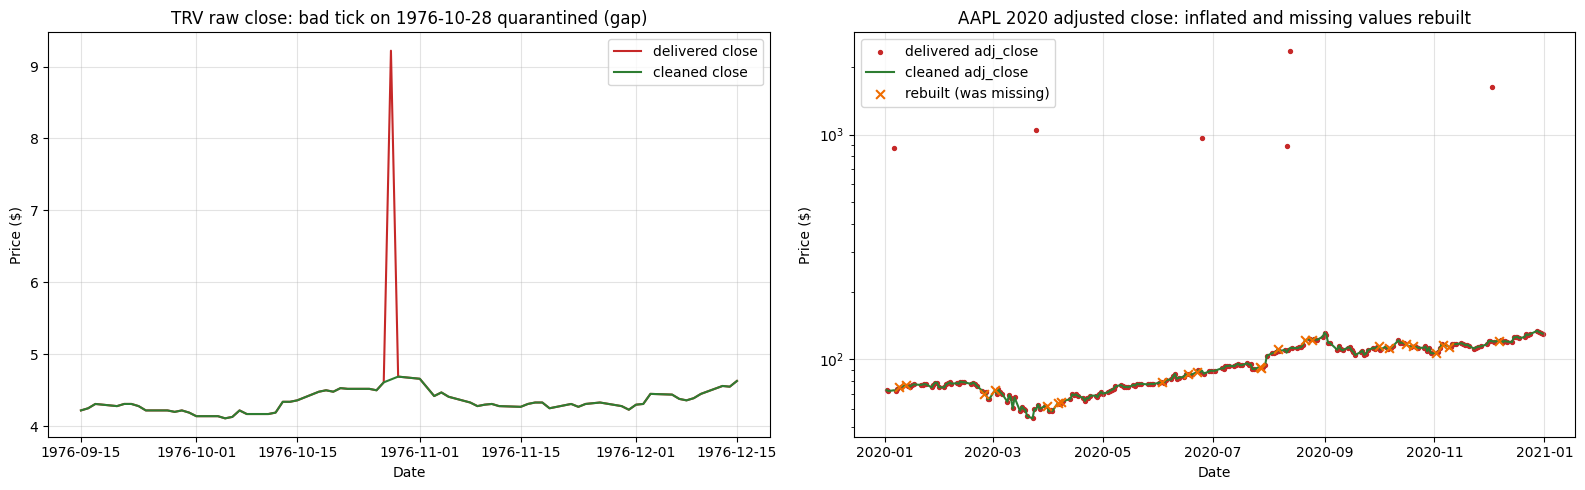

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

t, lo, hi = "TRV", "1976-09-15", "1976-12-15"
b = dedup[(dedup["ticker"] == t) & dedup["ts"].between(lo, hi)]
a = clean[(clean["ticker"] == t) & clean["ts"].between(lo, hi)]
axes[0].plot(pd.to_datetime(b["ts"]), b["close"], color="#c62828", lw=1.5, label="delivered close")
axes[0].plot(pd.to_datetime(a["ts"]), a["close"], color="#2e7d32", lw=1.5, label="cleaned close")
axes[0].set_title("TRV raw close: bad tick on 1976-10-28 quarantined (gap)")

t, lo, hi = "AAPL", "2020-01-01", "2020-12-31"
b = dedup[(dedup["ticker"] == t) & dedup["ts"].between(lo, hi)]
a = clean[(clean["ticker"] == t) & clean["ts"].between(lo, hi)]
was_missing = a[a["adj_close_original"].isna()]
axes[1].scatter(pd.to_datetime(b["ts"]), b["adj_close"], s=8, color="#c62828", label="delivered adj_close")
axes[1].plot(pd.to_datetime(a["ts"]), a["adj_close"], color="#2e7d32", lw=1.5, label="cleaned adj_close")
axes[1].scatter(pd.to_datetime(was_missing["ts"]), was_missing["adj_close"], marker="x", color="#ef6c00", s=40,
                label="rebuilt (was missing)", zorder=3)
axes[1].set_yscale("log")
axes[1].set_title("AAPL 2020 adjusted close: inflated and missing values rebuilt")

for ax in axes:
    ax.grid(True, alpha=0.35)
    ax.legend()
    ax.set_xlabel("Date")
    ax.set_ylabel("Price ($)")
plt.tight_layout()
plt.show()

### Save

In [23]:
with closing(sqlite3.connect(DB_PATH)) as conn:
    clean.to_sql("ohlc_hw_cleaned", conn, if_exists="replace", index=False)
    quarantine.to_sql("ohlc_hw_quarantine", conn, if_exists="replace", index=False)
    quality_report.to_sql("ohlc_hw_quality_report", conn, if_exists="replace", index=False)
    ticker_audit.to_sql("ohlc_hw_ticker_audit", conn, if_exists="replace", index=False)
    conn.commit()

    saved = pd.read_sql_query("SELECT * FROM ohlc_hw_cleaned", conn)
    raw_hash_after = table_hash(conn, "ohlc_hw")
    typeof_ts = conn.execute("SELECT DISTINCT typeof(ts) FROM ohlc_hw_cleaned").fetchall()

assert len(saved) == len(clean) and validate(saved, factors).all()
assert raw_hash_after == raw_hash_before, "raw table changed!"
print(f"ohlc_hw_cleaned: {len(saved):,} rows, ts stored as {typeof_ts}; raw ohlc_hw unchanged (sha256 {raw_hash_before[:12]}...)")
print("Latest cleaned observation:", saved["ts"].max())

ohlc_hw_cleaned: 368,243 rows, ts stored as [('text',)]; raw ohlc_hw unchanged (sha256 1e62233eaa62...)
Latest cleaned observation: 2024-12-06


## 1.4 Injected examples

Many required faults are absent from this delivery, so each detector and repair is checked on a small hand-built frame with known answers.

In [24]:
toy_days = pd.bdate_range("2024-01-01", periods=8).strftime("%Y-%m-%d")
toy_ref = pd.DataFrame([(t, d, 10.0 + i, (10.0 + i) * 0.5) for t in ["AAA", "BBB"] for i, d in enumerate(toy_days)],
                       columns=["ticker", "ts", "close", "adj_close"])
toy_factors = reference_factors(toy_ref)


def bar(t, i, o=None, hi=None, lo=None, c=None, adj="auto", v=1000.0):
    c = 10.0 + i if c is None else c
    o = c if o is None else o
    hi = max(o, c) + 0.5 if hi is None else hi
    lo = min(o, c) - 0.5 if lo is None else lo
    adj = c * 0.5 if adj == "auto" else adj
    return {"ticker": t, "ts": toy_days[i], "open": o, "high": hi, "low": lo, "close": c, "adj_close": adj, "volume": v}


toy = pd.DataFrame([
    bar("AAA", 0), bar("AAA", 1), bar("AAA", 1),               # exact duplicate
    bar("AAA", 3, adj=np.nan),                                 # day 2 removed; missing adj_close
    bar("AAA", 4, c=np.nan, o=13.2, hi=13.6, lo=12.8),        # missing close
    bar("AAA", 5, o=15, hi=15.2, lo=14.8, c=15.9),             # high < close
    bar("AAA", 6, v=np.nan),                                   # missing volume
    {**bar("AAA", 7), "open": np.nan, "high": np.nan, "low": np.nan, "close": np.nan},  # all prices missing
    bar("BBB", 0, o=np.nan, hi=10.5, lo=9.5),                  # leading gap
    bar("BBB", 1), bar("BBB", 2),
    bar("BBB", 3), bar("BBB", 3, c=13.4),                      # conflicting key
    bar("BBB", 4, c=-1.0, o=12.2, hi=12.5, lo=11.8),           # negative close
    bar("BBB", 5, c=np.inf, o=12.1, hi=12.5, lo=11.5),         # non-finite close
    bar("BBB", 6, adj=7.0 * 12),                               # inflated adj_close
    bar("BBB", 7),
])

toy_missing = find_missing_days(toy, toy_ref)
print("\n".join(summarize_missing_days(toy, toy_missing)))
display(toy_missing)
toy_issues = pd.concat([detect_duplicates(toy), detect_missing_values(toy.drop_duplicates(VALUE_COLS)),
                        detect_price_problems(toy.drop_duplicates(VALUE_COLS))], ignore_index=True)
toy_issues

Ticker AAA is missing 1 trading days between 2024-01-01 and 2024-01-10
Ticker BBB is missing 0 trading days between 2024-01-01 and 2024-01-10


,ticker,ts
0,AAA,2024-01-03


,ticker,issue_type,issue_date,description,severity
0,AAA,exact_duplicate,2024-01-02,1 extra identical copies,low
1,BBB,conflicting_key,2024-01-04,another row for this key has different values ...,high
2,BBB,conflicting_key,2024-01-04,another row for this key has different values ...,high
3,AAA,missing_open,2024-01-10,open is missing,high
4,BBB,missing_open,2024-01-01,open is missing,high
5,AAA,missing_high,2024-01-10,high is missing,high
6,AAA,missing_low,2024-01-10,low is missing,high
7,AAA,missing_close,2024-01-05,close is missing,high
8,AAA,missing_close,2024-01-10,close is missing,high
9,AAA,missing_adj_close,2024-01-04,adj_close is missing,medium


In [25]:
toy_clean, toy_q, toy_removed, toy_dupes = clean_ohlc(toy, toy_factors)
display(toy_clean[KEY + ALL_PRICES + ["volume", "price_repair", "adj_close_repair", "volume_filled"]])
display(toy_q[KEY + PRICE_COLS + ["reason"]])

assert toy_missing.values.tolist() == [["AAA", toy_days[2]]]
assert toy_dupes == 1 and len(toy_removed) == 1
assert set(toy_q["reason"]) == {"conflicting values for the same (ticker, ts)", "no earlier valid price to fill from (leading gap)"}
row = toy_clean.set_index(KEY)
assert row.loc[("AAA", toy_days[4]), "close"] == row.loc[("AAA", toy_days[3]), "close"]
assert row.loc[("AAA", toy_days[5]), "price_repair"] == "bad_bar_ffill"
assert row.loc[("AAA", toy_days[6]), "volume"] == 0 and row.loc[("AAA", toy_days[6]), "volume_filled"] == 1
assert row.loc[("BBB", toy_days[4]), "close"] > 0 and np.isfinite(row.loc[("BBB", toy_days[5]), "close"])
assert row.loc[("AAA", toy_days[3]), "adj_close"] == 13 * 0.5
assert row.loc[("BBB", toy_days[6]), "adj_close"] == 16 * 0.5
assert validate(toy_clean, toy_factors).all()
print("injected repair checks passed")

,ticker,ts,open,high,low,close,adj_close,volume,price_repair,adj_close_repair,volume_filled
0,AAA,2024-01-01,10.0,10.5,9.5,10.0,5.0,1000.0,,,0
1,AAA,2024-01-02,11.0,11.5,10.5,11.0,5.5,1000.0,,,0
2,AAA,2024-01-04,13.0,13.5,12.5,13.0,6.5,1000.0,,reference_factor,0
3,AAA,2024-01-05,13.2,13.6,12.8,13.0,6.5,1000.0,ffill:close,reference_factor,0
4,AAA,2024-01-08,13.2,13.6,12.8,13.0,6.5,1000.0,bad_bar_ffill,reference_factor,0
5,AAA,2024-01-09,16.0,16.5,15.5,16.0,8.0,0.0,,,1
6,BBB,2024-01-02,11.0,11.5,10.5,11.0,5.5,1000.0,,,0
7,BBB,2024-01-03,12.0,12.5,11.5,12.0,6.0,1000.0,,,0
8,BBB,2024-01-05,12.2,12.5,11.8,12.0,6.0,1000.0,ffill:close,reference_factor,0
9,BBB,2024-01-08,12.1,12.5,11.5,12.0,6.0,1000.0,ffill:close,reference_factor,0


,ticker,ts,open,high,low,close,reason
0,BBB,2024-01-04,13.0,13.5,12.5,13.0,"conflicting values for the same (ticker, ts)"
1,BBB,2024-01-04,13.4,13.9,12.9,13.4,"conflicting values for the same (ticker, ts)"
2,BBB,2024-01-01,NaN,10.5,9.5,10.0,no earlier valid price to fill from (leading gap)


injected repair checks passed


In [26]:
rng = np.random.default_rng(7)
r = rng.normal(0, 0.01, 60)
r[20], r[40] = 0.15, -0.15
tails = pd.DataFrame({"ticker": "TAIL", "ts": pd.bdate_range("2024-01-01", periods=61).strftime("%Y-%m-%d"),
                      "close": 100 * np.cumprod(np.r_[1, 1 + r])})
flat = tails.assign(ticker="FLAT", close=50.0)
spike = tails.assign(ticker="SPIKE", close=20.0)
spike.loc[30, "close"] = 40.0
demo = pd.concat([tails, flat, spike], ignore_index=True)
for c in ["open", "high", "low"]:
    demo[c] = demo["close"]
demo["volume"] = np.where((demo["ticker"] == "SPIKE") & (demo["close"] == 40.0), 0, 1000)

demo_ret, demo_flag = screen_returns(demo)
print("TAIL flagged returns:", demo_ret[demo_flag & (demo["ticker"] == "TAIL")].round(3).tolist())
print("FLAT (zero std) flags:", int(demo_flag[demo["ticker"] == "FLAT"].sum()))
print("SPIKE bad ticks:", demo.loc[find_bad_ticks(demo, demo_flag), ["ticker", "ts", "close"]].values.tolist())
assert (demo_ret[demo_flag & (demo["ticker"] == "TAIL")] > 0).any() and (demo_ret[demo_flag & (demo["ticker"] == "TAIL")] < 0).any()
assert demo_flag[demo["ticker"] == "FLAT"].sum() == 0
assert find_bad_ticks(demo, demo_flag).sum() == 1

TAIL flagged returns: [0.15, -0.15]
FLAT (zero std) flags: 0
SPIKE bad ticks: [['SPIKE', '2024-02-12', 40.0]]
